In [31]:
import mc_discrete_1d_metadynamics as mc
import cyclic_systems as cs
import matplotlib.pyplot as plt
import numpy as np
import importlib
importlib.reload(mc)
importlib.reload(cs)

<module 'cyclic_systems' from '/home/jonathan/Documents/grabelab/sampling-scheme-development/mtd_gaussian_width_optimization/cyclic_systems.py'>

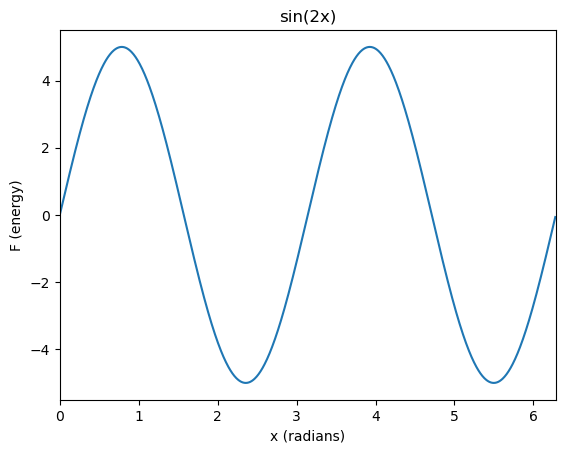

1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000004
1.0
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000004
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002
1.0000000000000002


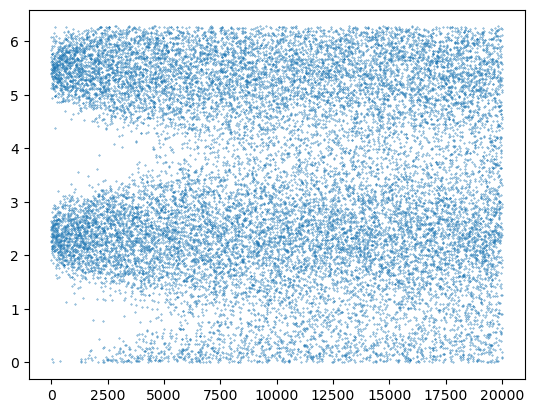

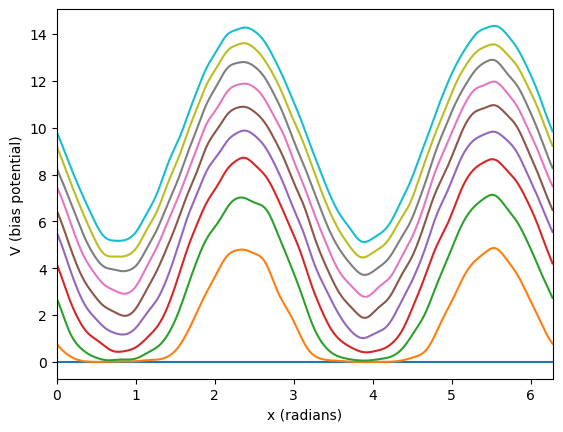

In [61]:
nrounds = 20000
sigma = 0.1#0.06
omega = 1
deltaT = 10
kB=1
T=1

npts = 1000
A=5
s1 = cs.F_2sine(npts, A)
s1.plot()
x, F = s1.evaluate()

t, bin_trj, V = mc.monte_carlo_discrete_1d_metadynamics(s1, sigma, omega, deltaT, kB, T, nrounds)

plt.scatter(t, x[bin_trj], s=0.1)
plt.show()

for t_plot in t[::int(nrounds/10)]:
    plt.plot(x, V[t_plot])
    plt.xlabel("x (radians)")
    plt.ylabel("V (bias potential)")
    plt.xlim(0, 2*np.pi)

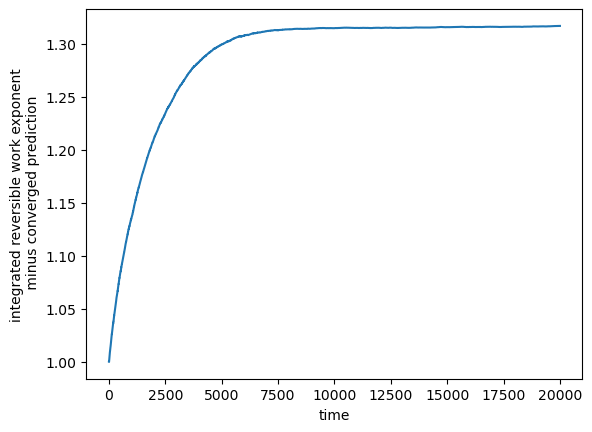

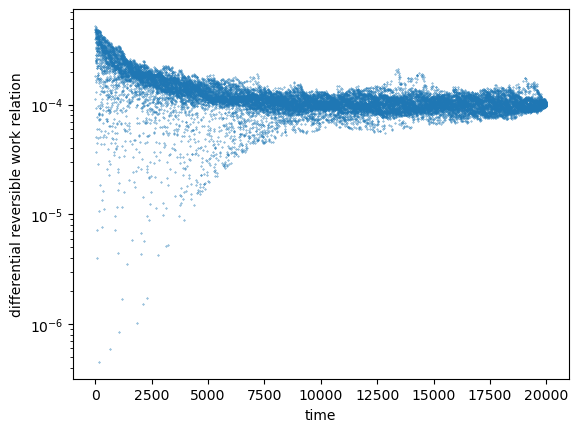

/tmp/ipykernel_58274/3162698390.py:37: RuntimeWarning: invalid value encountered in divide
  q = (np.exp(ct/deltaT)-1)/t


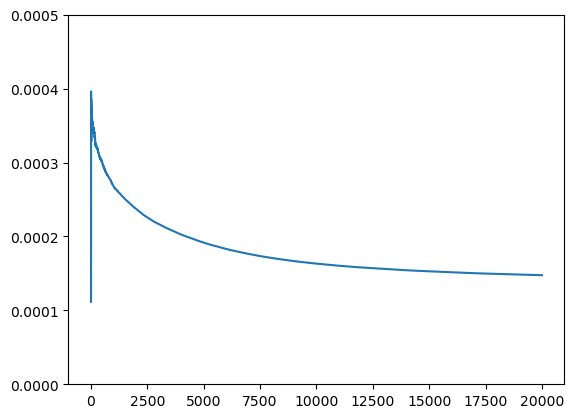

In [62]:
F_v = -V[-1]*(T+deltaT)/deltaT #the estimated free energy surface at the end of the simulation
FpV = V[:-1]+F_v #the biased free energy surface at each round of the simulation

if False:
    plt.plot(F_v)
    plt.show()

    plt.imshow(FpV, extent=[x[0], x[-1], 0, nrounds], aspect='auto', origin='lower', cmap='viridis')
    plt.colorbar()
    plt.show()

Z_0 = np.sum(np.exp(-F_v/(kB*T)))
Z_V = np.sum(np.exp(-FpV/(kB*T)), axis = 1)

ct = -kB*T*np.log(Z_V/Z_0)

Z_0_T_plus_deltaT = np.sum(np.exp(-F_v/(kB*(T+deltaT))))

q2 = np.exp(ct/(kB*deltaT)) - (t*omega/(kB*deltaT)) * ((Z_0**(T/deltaT))/(Z_0_T_plus_deltaT**(T/deltaT+1)))
plt.plot(q2, label="q2")
plt.ylabel("integrated reversible work exponent\n minus converged prediction")
plt.xlabel("time")
plt.show()

dct = np.diff(ct)
dt = np.diff(t)
dcdt = dct/dt

#plt.plot(1/(deltaT/dcdt-t[1:]), label="dcdt")
plt.scatter(t[1:], 1/(deltaT/dcdt-t[1:]), label="dcdt", s=0.1)
plt.xlabel("time")
plt.ylabel("differential reversible work relation")
plt.yscale('log')
plt.show()

#from Branduardi
q = (np.exp(ct/deltaT)-1)/t
plt.plot(q, label="q")
plt.ylim(0,0.0005)
plt.show()